In [3]:
import math
import numpy as np
from tqdm import tqdm
# from fiblat import sphere_lattice, cube_lattice

# Load the fibonacci lattice

In [4]:
# sphere = np.load('sphere_100.npy')
sphere = np.load('sphere_2000.npy')

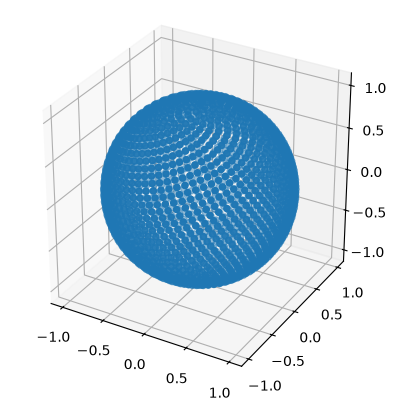

In [5]:
# visualize fibonacci lattice sphere
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
 
# creating an empty canvas
fig = plt.figure()
ax = plt.axes(projection="3d")
ax.set_aspect('equal')
ax.scatter3D(sphere[:, 0], sphere[:, 1], sphere[:, 2]);
 
# Showing the above plot
plt.show()

In [6]:
print("radius of fibonacci lattice sphere: ", sphere[0, 0]**2+sphere[0, 1]**2+sphere[0, 2]**2)

radius of fibonacci lattice sphere:  1.0


In [7]:
# crop the top and bottom data where no future inferences will be done in those reigons
x = sphere[:, 0]
y = sphere[:, 1]
z = sphere[:, 2]

crop_threshold = 0.6

x_crop = []
y_crop = []
z_crop = []
for i in range(2000):
    if (y[i] < crop_threshold and y[i] > -crop_threshold):
        x_crop.append(x[i])
        y_crop.append(y[i])
        z_crop.append(z[i])

ray_size = len(x_crop)
print("point num after crop:", ray_size)

point num after crop: 1201


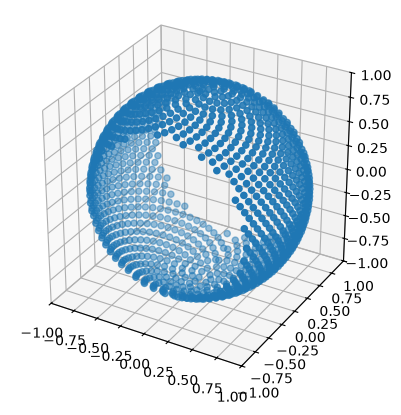

In [8]:
# visualize fibonacci lattice sphere
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
 
# creating an empty canvas
fig = plt.figure()
ax = plt.axes(projection="3d")
ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)
ax.set_zlim(-1, 1)
ax.set_aspect('equal', adjustable='box')
ax.scatter3D(x_crop, y_crop, z_crop);
 
# Showing the above plot
plt.show()

# 1. Create views for training

In [11]:
volume_dimension = 255
block_dimension = volume_dimension
r_min = math.sqrt((block_dimension/2)**2 + (block_dimension/2)**2 + (block_dimension/2)**2)
r_max = 3.5*math.sqrt((volume_dimension/2)**2 + (volume_dimension/2)**2 + (volume_dimension/2)**2)
print("r_min for each block:", r_min)
print("r_max for each block:", r_max)

r_min for each block: 220.83647796503186
r_max for each block: 772.9276728776115


In [12]:
# create the views tensor for the demo trajectory

views = np.zeros((1, ray_size, 1, 1, 9)) # 9: 3 of camera position; 3 of focal point; 3 of up view
for j in range(ray_size):
    camera_position = np.array([x_crop[j]*r_max, y_crop[j]*r_max, z_crop[j]*r_max])
    views[0, j, 0, 0, 0:3] = camera_position
    views[0, j, 0, 0, 3:6] = np.array([0, 0, 0])
    views[0, j, 0, 0, 6:9] = np.array([0, -1, 0])

Text(0.5, 0, 'Z')

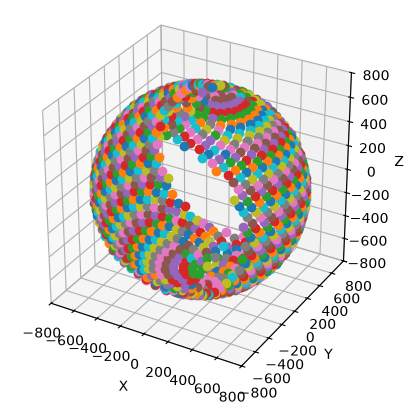

In [13]:
# Visualizing the views data (micro-block and rays)
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Define the data points for the 3D line
colors = ['blue', 'red', 'green']

# Create a new figure and add a 3D subplot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

select = 0

for i in range(1):
# for i in range(27):
    for j in range(ray_size):
        xs = []
        ys = []
        zs = []
#         for k in range(sample_size):
        for k in range(1):
    #         for l in range(up_size):
            xs.append(views[i, j, k, 0, 0])
            ys.append(views[i, j, k, 0, 1])
            zs.append(views[i, j, k, 0, 2])
    #         y = [views[0, j, k, 0, 4]]
    #         z = [views[0, j, k, 0, 5]]
    #         x = [views[0, i, 0, j, 3], views[0, i, 0, j, 6]]
    #         y = [views[0, i, 0, j, 4], views[0, i, 0, j, 7]]
    #         z = [views[0, i, 0, j, 5], views[0, i, 0, j, 8]]
        ax.plot(xs, ys, zs, marker='o', label='3D Line')

ax.set_xlim(-800, 800)
ax.set_ylim(-800, 800)
ax.set_zlim(-800, 800)
    
ax.set_aspect('equal', adjustable='box')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

Text(0.5, 0, 'Z')

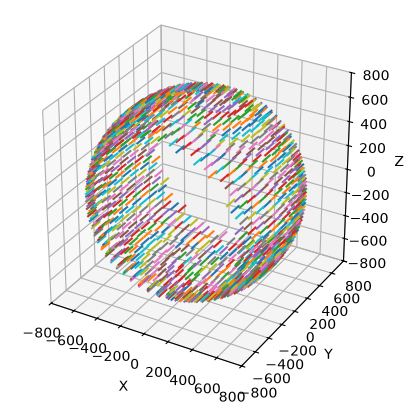

In [14]:
# Visualizing the views data (up directions)
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Create a new figure and add a 3D subplot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# for i in range(block_size):
for i in range(1):
    for j in range(ray_size):
#         for k in range(sample_size):
        for k in range(1):
            for l in range(1):
                xs = [views[i, j, k, l, 0], views[i, j, k, l, 0] + views[i, j, k, l, 6]*100]
                ys = [views[i, j, k, l, 1], views[i, j, k, l, 1] + views[i, j, k, l, 7]*100]
                zs = [views[i, j, k, l, 2], views[i, j, k, l, 2] + views[i, j, k, l, 8]*100]
#                 print("=======")
#                 print(x)
#                 print(y)
#                 print(z)
#                 print(math.sqrt(views[i, j, k, l, 6]**2 + views[i, j, k, l, 7]**2 + views[i, j, k, l, 8]**2))
#                 ax.plot(x, y, z, marker='o', label='3D Line')
                ax.plot(xs, ys, zs, label='3D Line')

ax.set_xlim(-800, 800)
ax.set_ylim(-800, 800)
ax.set_zlim(-800, 800)
    
ax.set_aspect('equal', adjustable='box')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# 2. Create views for testing (demo)

In [15]:
demo_point_num = 120

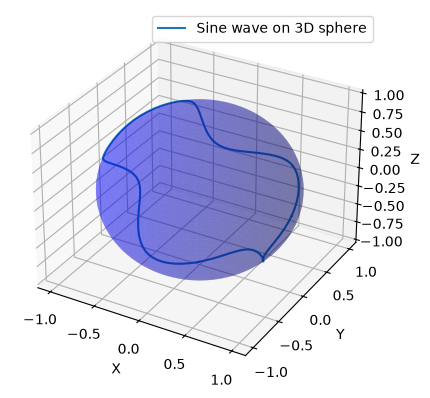

In [16]:
# sine circle
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Parameters
radius = 1
amplitude = 0.3  # Amplitude of the sine wave
frequency = 4    # Frequency of the sine wave

# Generate an array of angles for the latitude (phi) and longitude (theta)
theta = np.linspace(0, 2 * np.pi, demo_point_num)  # Longitude from 0 to 2*pi
phi = amplitude * np.sin(frequency * theta)    # Latitude varies with a sine wave

# Convert spherical coordinates to Cartesian coordinates
demo_x = radius * np.cos(phi) * np.cos(theta)
demo_z = radius * np.cos(phi) * np.sin(theta)
demo_y = radius * np.sin(phi)

# Optional: plot the sine wave projected on the sphere
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot(demo_x, demo_y, demo_z, label='Sine wave on 3D sphere')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.legend()

# Plotting the sphere for reference
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 100)
x_sphere = radius * np.outer(np.cos(u), np.sin(v))
y_sphere = radius * np.outer(np.sin(u), np.sin(v))
z_sphere = radius * np.outer(np.ones(np.size(u)), np.cos(v))

ax.plot_surface(x_sphere, y_sphere, z_sphere, color='b', alpha=0.3)

plt.show()

In [17]:
# create the views tensor for the demo trajectory
demo_views = np.zeros((1, demo_point_num, 1, 1, 9)) # 9: 3 of camera position; 3 of focal point; 3 of up view
for j in range(demo_point_num):
    camera_position = np.array([demo_x[j]*r_max, demo_y[j]*r_max, demo_z[j]*r_max])
    demo_views[0, j, 0, 0, 0:3] = camera_position
    demo_views[0, j, 0, 0, 3:6] = np.array([0, 0, 0])
    demo_views[0, j, 0, 0, 6:9] = np.array([0, -1, 0])

Text(0.5, 0, 'Z')

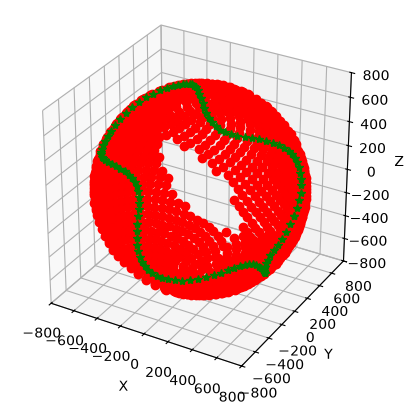

In [18]:
# Visualizing the views data (micro-block and rays)
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Define the data points for the 3D line
colors = ['blue', 'red', 'green']

# Create a new figure and add a 3D subplot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

select = 0

for i in range(1):
# for i in range(27):
    for j in range(ray_size):
        x = []
        y = []
        z = []
#         for k in range(sample_size):
        for k in range(1):
    #         for l in range(up_size):
            x.append(views[i, j, k, 0, 0])
            y.append(views[i, j, k, 0, 1])
            z.append(views[i, j, k, 0, 2])
    #         y = [views[0, j, k, 0, 4]]
    #         z = [views[0, j, k, 0, 5]]
    #         x = [views[0, i, 0, j, 3], views[0, i, 0, j, 6]]
    #         y = [views[0, i, 0, j, 4], views[0, i, 0, j, 7]]
    #         z = [views[0, i, 0, j, 5], views[0, i, 0, j, 8]]
        ax.plot(x, y, z, marker='o', label='3D Line', color='r')

for j in range(demo_point_num):
    x = []
    y = []
    z = []
    x.append(demo_views[0, j, 0, 0, 0])
    y.append(demo_views[0, j, 0, 0, 1])
    z.append(demo_views[0, j, 0, 0, 2])
    ax.plot(x, y, z, marker='*', label='3D Line', color='g')
    

ax.set_xlim(-800, 800)
ax.set_ylim(-800, 800)
ax.set_zlim(-800, 800)
    
ax.set_aspect('equal', adjustable='box')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

Text(0.5, 0, 'Z')

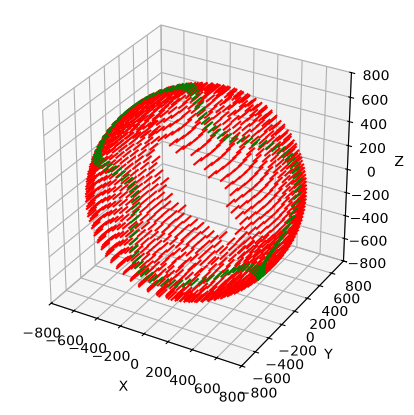

In [19]:
# Visualizing the views data (up directions)
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Create a new figure and add a 3D subplot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# for i in range(block_size):
for i in range(1):
    for j in range(ray_size):
#         for k in range(sample_size):
        for k in range(1):
            for l in range(1):
                xs = [views[i, j, k, l, 0], views[i, j, k, l, 0] + views[i, j, k, l, 6]*100]
                ys = [views[i, j, k, l, 1], views[i, j, k, l, 1] + views[i, j, k, l, 7]*100]
                zs = [views[i, j, k, l, 2], views[i, j, k, l, 2] + views[i, j, k, l, 8]*100]
#                 print("=======")
#                 print(x)
#                 print(y)
#                 print(z)
#                 print(math.sqrt(views[i, j, k, l, 6]**2 + views[i, j, k, l, 7]**2 + views[i, j, k, l, 8]**2))
#                 ax.plot(x, y, z, marker='o', label='3D Line')
                ax.plot(xs, ys, zs, label='3D Line', color='r')
    
for j in range(demo_point_num):
    xs = [demo_views[0, j, 0, 0, 0], demo_views[0, j, 0, 0, 0] + demo_views[0, j, 0, 0, 6]*100]
    ys = [demo_views[0, j, 0, 0, 1], demo_views[0, j, 0, 0, 1] + demo_views[0, j, 0, 0, 7]*100]
    zs = [demo_views[0, j, 0, 0, 2], demo_views[0, j, 0, 0, 2] + demo_views[0, j, 0, 0, 8]*100]
    ax.plot(xs, ys, zs, label='3D Line', color='g')

ax.set_xlim(-800, 800)
ax.set_ylim(-800, 800)
ax.set_zlim(-800, 800)
    
ax.set_aspect('equal', adjustable='box')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# 3 Save training and testing (demo) views

In [20]:
binary_view_name = 'trainviews_' +\
                    str(1) + "_" +\
                    str(ray_size) + "_" +\
                    str(1) + "_" +\
                    str(1) + ".bin"
# Save the array as a binary float32 file
views.tofile(binary_view_name)
print("View tensor has been saved as " + binary_view_name)


np.save('trainviews_' +\
        str(1) + "_" +\
        str(ray_size) + "_" +\
        str(1) + "_" +\
        str(1) + ".npy",\
        views)

View tensor has been saved as trainviews_1_1201_1_1.bin


In [21]:
binary_view_name = 'testviews_' +\
                    str(1) + "_" +\
                    str(demo_point_num) + "_" +\
                    str(1) + "_" +\
                    str(1) + ".bin"
# Save the array as a binary float32 file
demo_views.tofile(binary_view_name)
print("View tensor has been saved as " + binary_view_name)

np.save('testviews_' +\
        str(1) + "_" +\
        str(demo_point_num) + "_" +\
        str(1) + "_" +\
        str(1) + ".npy",\
        demo_views)

View tensor has been saved as testviews_1_120_1_1.bin
